In [1]:
import numpy as np
import utils
import comparison_utils
from tqdm import tqdm
import math
import matplotlib.pyplot as plt

n_classes = 8
class_labels = np.repeat(np.arange(8), 1000)

w2_block_files = []
sw2_block_files = []

for i in range(n_classes):
    for j in range(i, n_classes):
        w2_block_files.append(f"../mini_w2/block_{i}_{j}.npy")

for i in range(n_classes):
    for j in range(i, n_classes):
        sw2_block_files.append(f"../mini_sw/block_{i}_{j}_sw2.npy")

w2_matrix = utils.combine_distance_blocks(w2_block_files)
sw2_matrix = utils.combine_distance_blocks(sw2_block_files)

In [2]:
# qcd_class_level_sim = comparison_utils.avg_class_jaccard(
#     w2_matrix, sw2_matrix, class_labels, target_class=0, n_neighbors=2000
# )
# print(qcd_class_level_sim)

In [3]:
# neighbors = range(1, 999, 5)
# qcd_class_level_sims = [
#     comparison_utils.avg_class_jaccard(
#         w2_matrix, sw2_matrix, class_labels, target_class=0, n_neighbors=i
#     )
#     for i in tqdm(neighbors, total=len(neighbors))
# ]

In [4]:
def expected_matched_percentage(total_balls, draw_size, num_labels=8):
    """
    Calculate the expected number of matching labels between two draws
    of the same size, given an even distribution of `num_labels` in `total_balls`.
    """
    # how many balls of each label
    balls_per_label = total_balls // num_labels

    N = total_balls
    K = balls_per_label
    n = draw_size

    # the maximum possible count of any one label in a draw
    max_k = min(K, n)

    # Hypergeometric pmf for one draw: P(X = k)
    p = [
        math.comb(K, k) * math.comb(N - K, n - k) / math.comb(N, n)
        for k in range(max_k + 1)
    ]

    # Build the CDF: F_X(k) = P(X <= k)
    cdf = [sum(p[: i + 1]) for i in range(len(p))]

    # E[min(X, Y)] for two independent draws = sum_{k=1..max_k} [P(X >= k)]^2
    E_min = sum((1 - cdf[k - 1]) ** 2 for k in range(1, max_k + 1))

    # total expected matches across all labels
    return num_labels * E_min / draw_size


theory_sims = np.array([expected_matched_percentage(8000, i) for i in tqdm(range(1, 999, 5), total=999//5 + 1)])

100%|██████████| 200/200 [00:37<00:00,  5.40it/s]


In [5]:
# plt.plot(neighbors, theory_sims)
# plt.plot(neighbors, qcd_class_level_sims)

100%|██████████| 200/200 [02:27<00:00,  1.35it/s]


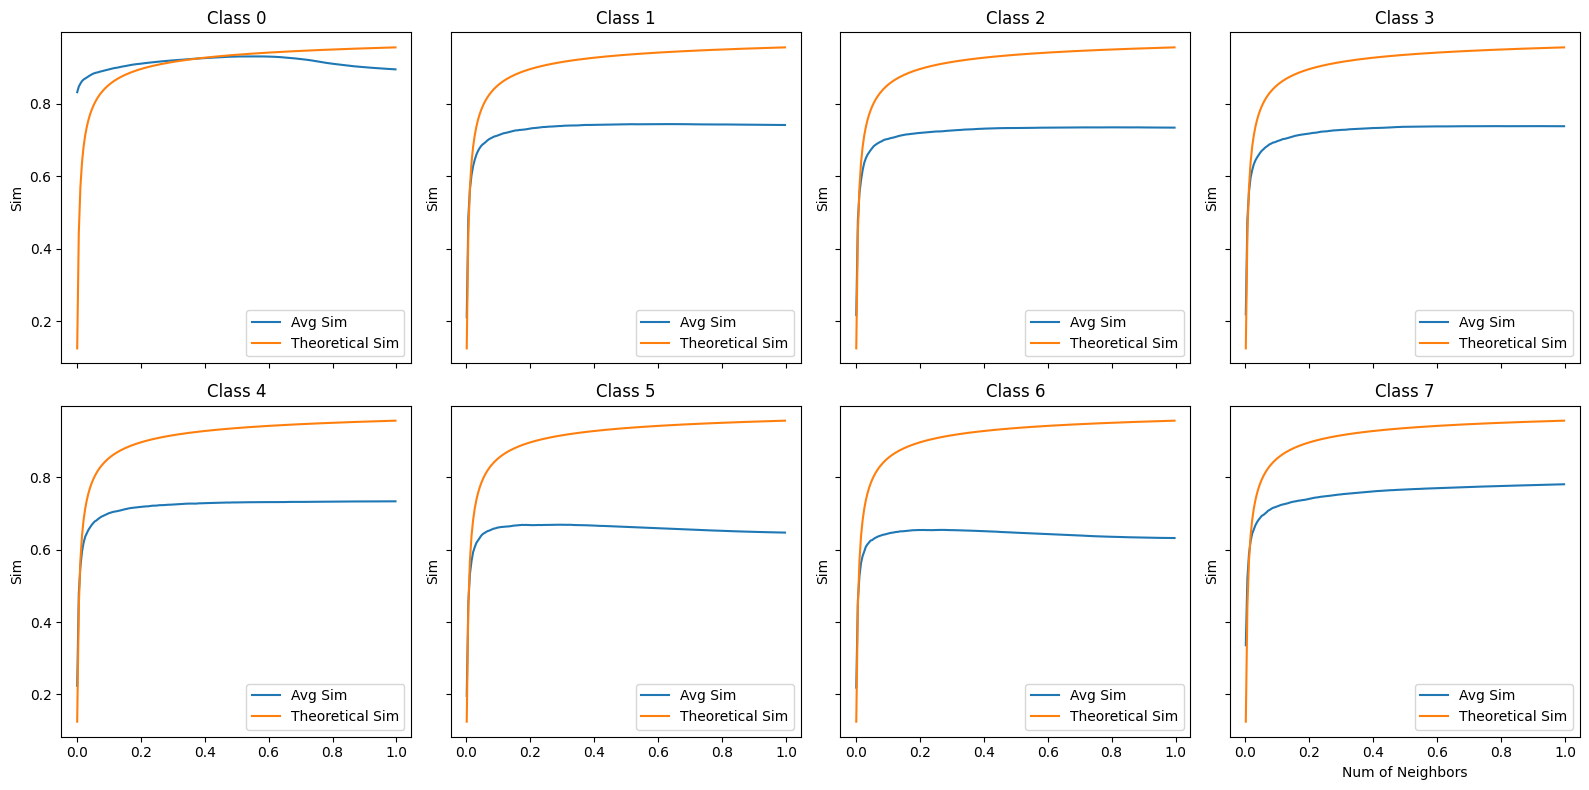

In [6]:
neighbors = np.array(range(1, 999, 5))
neighbor_percentages = neighbors / 999

all_class_sims = np.zeros((n_classes, len(neighbors)))

classes = np.arange(8)
n_plots = n_classes
ncols = 4
nrows = int(np.ceil(n_plots / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows), sharex=True, sharey=True)
axes = axes.flatten()

for ax, ind_class in zip(axes, classes):

    for i, n in tqdm(enumerate(neighbors), total=neighbors.size):
        all_class_sims[ind_class][i] = comparison_utils.avg_class_jaccard(w2_matrix, sw2_matrix, class_labels, target_class=ind_class, n_neighbors=n)

    ax.plot(neighbor_percentages, all_class_sims[ind_class], label='Avg Sim')
    ax.plot(neighbor_percentages, theory_sims, label='Theoretical Sim')
    ax.set_title(f'Class {ind_class}')
    ax.set_ylabel('Sim')
    ax.legend()
    
# common X-axis label on bottom
axes[-1].set_xlabel('Num of Neighbors')


plt.tight_layout()
plt.show()

In [7]:
print(all_class_sims)

[[0.832      0.84733333 0.85572727 ... 0.89566329 0.89539556 0.89510442]
 [0.211      0.48633333 0.56372727 ... 0.74163692 0.74154793 0.74153213]
 [0.217      0.47833333 0.55354545 ... 0.73432049 0.73423613 0.73426707]
 ...
 [0.196      0.45316667 0.53272727 ... 0.64705172 0.64695055 0.64685442]
 [0.219      0.45916667 0.52736364 ... 0.63193509 0.63192836 0.63185141]
 [0.336      0.52083333 0.58790909 ... 0.78003448 0.78012916 0.78021586]]


In [8]:
# neighbors = np.array(range(1, 999, 5))
# neighbor_percentages = neighbors / 999

# classes = np.arange(8)
# n_plots = n_classes
# ncols = 4
# nrows = int(np.ceil(n_plots / ncols))
# fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows), sharex=True, sharey=True)
# axes = axes.flatten()

# for ax, ind_class in zip(axes, classes):

#     ax.plot(neighbor_percentages, all_class_sims[ind_class], label='Avg Sim')
#     ax.plot(neighbor_percentages, theory_sims, label='Theoretical Sim')
#     ax.set_title(f'Class {ind_class}')
#     ax.set_ylabel('Sim')
#     ax.legend()
    
# # common X-axis label on bottom
# axes[-1].set_xlabel('Num of Neighbors')


# plt.tight_layout()
# plt.show()

In [9]:
all_class_sims_mean = np.mean(all_class_sims, axis=0)
print(all_class_sims_mean.shape)

(200,)


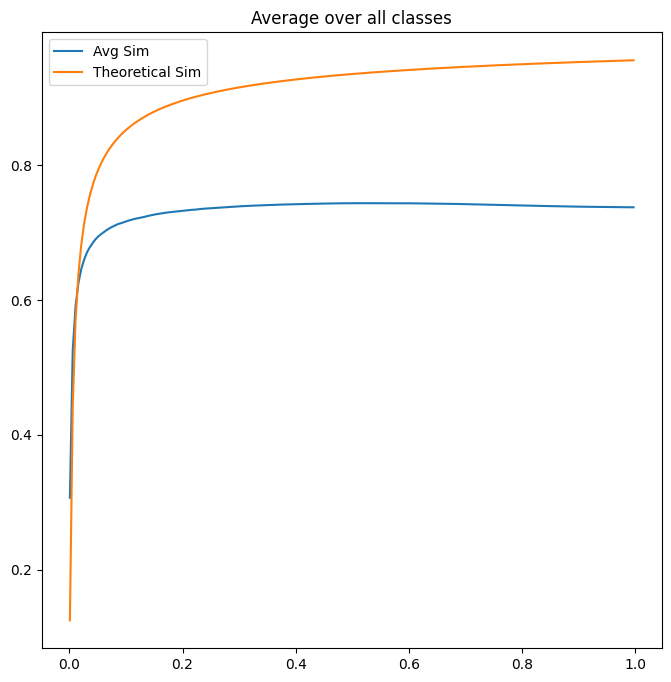

In [13]:
plt.figure(figsize=(8,8))
plt.plot(neighbor_percentages, all_class_sims_mean, label='Avg Sim')
plt.plot(neighbor_percentages, theory_sims, label='Theoretical Sim')
plt.title("Average over all classes")
plt.legend()
plt.show()